# Peticiones PQRS de personas de 60 años o más · DuckDB, Polars y Parquet

**Pregunta:** ¿cuántas peticiones se registraron **por mes y departamento** hechas por
personas de **80 años o más**?

**Datos:** los tres CSV completos de PQRS de la Superintendencia de Salud en
`kit/data/pqrs_completos/` (2023-II, 2024-I y 2024-II): 2.444.766 reportes, unos 1,8 GB.
Si no están, descargarlos desde `kit/` con `python 00_datos.py --descargar pqrs-completos`.

| Columna | Qué significa | Para qué la usamos |
|---|---|---|
| `periodo` | Año del reporte | Clave de tiempo (año) |
| `mes` | Mes del reporte (1–12) | Clave de tiempo (mes) |
| `pet_cod_depto` | Código DANE del departamento del **peticionario** | Agrupación |
| `afec_edad` | Edad de la **persona afectada** | Filtro (≥ 80) y agrupación |

Cada fila es una petición; no deduplicamos personas.

## Estrategia
1. **Inspeccionar** los archivos antes de leerlos: no todos tienen el mismo formato.
2. **Leer de forma diferida** (*lazy*): primero se describe la consulta y luego el motor
   decide cómo leer. Solo se leen 4 de las 38 columnas.
3. **Normalizar** tipos y códigos: año, mes, departamento a dos dígitos y edad numérica.
4. **Filtrar pronto** (edad ≥ 60), así la agrupación trabaja con menos filas.
5. **Agrupar** por año, mes, departamento y edad, y **contar**.
6. **Ordenar** para que el resultado sea legible y reproducible.
7. **Verificar** que DuckDB y Polars producen exactamente la misma tabla.
8. **Convertir a Parquet** (Snappy, particionado por año y mes), **medir** cada variante
   10 veces y decidir cuál es más rápida con el **test de Friedman** y comparaciones
   **post-hoc** par a par.

Ejecutar las celdas en orden con el kernel del `.venv` del curso.

## 1. Configuración

Importamos las bibliotecas y fijamos los parámetros en un solo lugar:

- `EDAD_MINIMA = 60`: el filtro es `afec_edad >= 60`.
- `N_EJECUCIONES = 10`: repeticiones medidas de cada variante en el benchmark.
- `ALFA = 0.05`: nivel de significancia de las pruebas estadísticas.
- `SEMILLA = 42`: hace reproducible el orden aleatorio de las variantes.
- `COLUMNAS`: las únicas cuatro columnas que necesita la pregunta.
- `TOTAL_REPORTES`: total de referencia de los tres CSV (de `kit/pqrs_fuentes.json`).

`REPOSITORIO` se busca subiendo desde la carpeta actual hasta encontrar
`kit/pqrs_fuentes.json`, así el cuaderno funciona en cualquier clon. Los productos
(Parquet y tiempos) se guardan en `kit/salidas/Read_pqrs/`, carpeta ignorada por git.

In [40]:
from pathlib import Path
from time import perf_counter
import itertools, platform, random, shutil

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from polars.testing import assert_frame_equal
from scipy import stats
from IPython.display import display

EDAD_MINIMA = 60
N_EJECUCIONES = 10
ALFA = 0.05
SEMILLA = 42
COLUMNAS = ['periodo', 'mes', 'pet_cod_depto', 'afec_edad']
TOTAL_REPORTES = 2_444_766

REPOSITORIO = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / 'kit/pqrs_fuentes.json').is_file()), None)
assert REPOSITORIO is not None, 'Abrir el cuaderno dentro del repositorio del curso'
KIT = REPOSITORIO / 'kit'
CSV_DIR = KIT / 'data/pqrs_completos'
OUT = KIT / 'salidas/Read_pqrs'
PARQUET_DIR = OUT / 'parquet_snappy'
OUT.mkdir(parents=True, exist_ok=True)

ARCHIVOS = sorted(CSV_DIR.glob('PQRD_*.csv'))
assert len(ARCHIVOS) == 3, 'Descargar con: python 00_datos.py --descargar pqrs-completos'
display(pl.DataFrame({'archivo': [a.name for a in ARCHIVOS],
                      'MB': [round(a.stat().st_size / 1e6, 1) for a in ARCHIVOS]}))
print('python', platform.python_version(), '| duckdb', duckdb.__version__, '| polars', pl.__version__)

archivo,MB
str,f64
"""PQRD_2023_II.csv""",532.7
"""PQRD_2024_I.csv""",576.7
"""PQRD_2024_II.csv""",706.8


python 3.12.14 | duckdb 1.4.1 | polars 1.35.2


## 2. Inspeccionar las cabeceras antes de leer

Antes de leer 1,8 GB conviene mirar la primera línea de cada archivo. Los tres CSV
**no usan el mismo separador**: 2023-II y 2024-II usan `;` y 2024-I usa `,`. Si leyéramos
los tres con un único `read_csv` y un comodín (`PQRD_*.csv`), uno de ellos quedaría como
una sola columna gigante.

- `open(ruta, encoding='utf-8-sig')` abre el archivo y descarta el BOM, la marca invisible
  que algunos programas ponen al inicio de un UTF-8.
- `readline()` lee solo la cabecera, no el archivo completo.
- La función cuenta `;` y `,` y elige el más frecuente.
- `FUENTES` guarda pares `(ruta, separador)`, que reutilizan DuckDB y Polars.

In [41]:
def detectar_separador(ruta):
    with open(ruta, encoding='utf-8-sig') as archivo:
        cabecera = archivo.readline()
    return ';' if cabecera.count(';') > cabecera.count(',') else ','

FUENTES = [(ruta, detectar_separador(ruta)) for ruta in ARCHIVOS]
for ruta, separador in FUENTES:
    print(f'{ruta.name}: separador {separador!r}')

PQRD_2023_II.csv: separador ';'
PQRD_2024_I.csv: separador ','
PQRD_2024_II.csv: separador ';'


# Parte A · DuckDB: la consulta en SQL

DuckDB es una base de datos analítica que se ejecuta dentro del proceso de Python, sin
servidor. Permite consultar un CSV o un Parquet directamente con SQL, sin cargarlo antes
en memoria, y usa todos los núcleos del procesador.

## A1. Una vista sobre los tres CSV

- `duckdb.connect()` sin ruta abre una base de datos **en memoria**.
- `read_csv(...)` lee un archivo: `delim` es el separador detectado, `header=true` toma la
  primera fila como nombres de columna y `all_varchar=true` lee **todo como texto**. Así
  se conservan los ceros iniciales (`05`) y DuckDB no tiene que adivinar tipos.
- `UNION ALL BY NAME` apila los tres archivos emparejando columnas **por nombre**, no por
  posición. `ALL` conserva todas las filas, sin eliminar duplicados.
- `CREATE VIEW` guarda la consulta, **no los datos**: todavía no se ha leído nada.

La función `sql_union_csv` construye ese SQL; la reutilizaremos en el benchmark.

In [42]:
def sql_union_csv(fuentes):
    lecturas = [f"SELECT * FROM read_csv('{ruta}', delim='{sep}', header=true, all_varchar=true)"
                for ruta, sep in fuentes]
    return '\nUNION ALL BY NAME\n'.join(lecturas)

con = duckdb.connect()
con.execute(f'CREATE OR REPLACE VIEW pqrs AS {sql_union_csv(FUENTES)}')
print(sql_union_csv(FUENTES))

SELECT * FROM read_csv('/home/kyoda/Proyectos/Universidad/Especializacion/big-data-postgraduate-bpineda/kit/data/pqrs_completos/PQRD_2023_II.csv', delim=';', header=true, all_varchar=true)
UNION ALL BY NAME
SELECT * FROM read_csv('/home/kyoda/Proyectos/Universidad/Especializacion/big-data-postgraduate-bpineda/kit/data/pqrs_completos/PQRD_2024_I.csv', delim=',', header=true, all_varchar=true)
UNION ALL BY NAME
SELECT * FROM read_csv('/home/kyoda/Proyectos/Universidad/Especializacion/big-data-postgraduate-bpineda/kit/data/pqrs_completos/PQRD_2024_II.csv', delim=';', header=true, all_varchar=true)


## A2. Comprobar la lectura

- `count(*)` obliga a recorrer los tres archivos. Compararlo con el total de referencia
  confirma que ninguno se leyó con un separador equivocado.
- `fetchone()[0]` toma el único valor del resultado.
- `LIMIT 5` muestra unas pocas filas de las cuatro columnas; `.pl()` entrega el
  resultado como DataFrame de Polars para mostrarlo.

In [43]:
filas = con.sql('SELECT count(*) FROM pqrs').fetchone()[0]
print(f'Filas leídas: {filas:,}')
assert filas == TOTAL_REPORTES
display(con.sql('SELECT periodo, mes, pet_cod_depto, afec_edad FROM pqrs LIMIT 5').pl())

Filas leídas: 2,444,766


periodo,mes,pet_cod_depto,afec_edad
str,str,str,str
"""2023""","""7""","""11""","""69"""
"""2023""","""7""","""11""","""35"""
"""2023""","""7""","""70""","""77"""
"""2023""","""7""","""76""","""71"""
"""2023""","""7""","""08""","""48"""


## A3. Normalizar tipos y códigos

Escribimos la limpieza **una sola vez** en `SQL_LIMPIO` y la guardamos como la vista
`pqrs_limpio`; las consultas siguientes parten de ella.

- `CAST(periodo AS INTEGER) AS anio`: el año pasa de texto a entero. Lo necesitamos porque
  los meses 7–12 existen en 2023 **y** en 2024; agrupar solo por mes mezclaría julio de
  2023 con julio de 2024.
- `CAST(mes AS INTEGER)`: ordena 1, 2, …, 12 y no `'1', '10', '11', '12', '2'`, como haría
  el texto.
- `trim` quita espacios y `lpad(..., 2, '0')` rellena con ceros a la izquierda: en 2024-I
  Antioquia aparece como `5` y en los otros archivos como `05`. Sin esto, el mismo
  departamento quedaría repartido en dos grupos.
- `coalesce(..., 'SIN DATO')` reemplaza los vacíos (`NULL`): los reportes sin departamento
  no se pierden y forman su propio grupo.
- `CAST(afec_edad AS INTEGER)`: compara edades como números. Como texto, `'9' >= '80'` es
  verdadero.

La segunda consulta muestra los códigos que cambian al normalizar.

In [44]:
SQL_LIMPIO = """
SELECT CAST(periodo AS INTEGER)                                AS anio,
       CAST(mes AS INTEGER)                                    AS mes,
       coalesce(lpad(trim(pet_cod_depto), 2, '0'), 'SIN DATO') AS cod_depto,
       CAST(afec_edad AS INTEGER)                              AS edad
FROM pqrs
"""
con.execute(f'CREATE OR REPLACE VIEW pqrs_limpio AS {SQL_LIMPIO}')

display(con.sql("""
    SELECT DISTINCT pet_cod_depto AS original,
           coalesce(lpad(trim(pet_cod_depto), 2, '0'), 'SIN DATO') AS normalizado
    FROM pqrs
    WHERE pet_cod_depto IS NULL OR length(trim(pet_cod_depto)) < 2
    ORDER BY normalizado
""").pl())
display(con.sql('SELECT * FROM pqrs_limpio LIMIT 5').pl())

original,normalizado
str,str
"""5""","""05"""
"""8""","""08"""
null,"""SIN DATO"""


anio,mes,cod_depto,edad
i32,i32,str,i32
2023,7,"""11""",69
2023,7,"""11""",35
2023,7,"""70""",77
2023,7,"""76""",71
2023,7,"""08""",48


## A4. Filtrar, agrupar, contar y ordenar

SQL se **escribe** en un orden, pero se **evalúa** en otro:
`FROM → WHERE → GROUP BY → SELECT → ORDER BY`.

- `FROM pqrs_limpio`: parte de los datos ya normalizados.
- `WHERE edad >= ?`: el `?` es un **parámetro**; su valor (`EDAD_MINIMA`) se pasa aparte,
  en la lista `[EDAD_MINIMA]`. Así no pegamos valores dentro del texto SQL. Filtrar antes
  de agrupar reduce 2,4 millones de filas a menos de 200 mil.
- `GROUP BY anio, mes, cod_depto, edad`: forma un grupo por cada combinación.
- `count(*) AS peticiones`: cuenta las filas de cada grupo.
- `ORDER BY ...`: orden cronológico y luego departamento y edad. Sin `ORDER BY` el orden
  de salida no está garantizado, porque el motor trabaja en paralelo.

Primero definimos la consulta; la celda siguiente la ejecuta.

In [45]:
CLAVES = ['anio', 'mes', 'cod_depto', 'edad']
SQL_DETALLE = """
SELECT anio, mes, cod_depto, edad, count(*) AS peticiones
FROM pqrs_limpio
WHERE edad >= ?
GROUP BY anio, mes, cod_depto, edad
ORDER BY anio, mes, cod_depto, edad
"""

`%%time` mide la celda completa: *Wall time* es el tiempo real transcurrido. Aquí
DuckDB lee los tres CSV, normaliza, filtra, agrupa y ordena en una sola pasada.
`detalle_duckdb` será la **tabla de referencia** del resto del cuaderno.

In [46]:
%%time
detalle_duckdb = con.execute(SQL_DETALLE, [EDAD_MINIMA]).pl()
print(detalle_duckdb.shape)
display(detalle_duckdb.head(10))

(21162, 5)


anio,mes,cod_depto,edad,peticiones
i32,i32,str,i32,i64
2023,7,"""05""",60,353
2023,7,"""05""",61,359
2023,7,"""05""",62,334
2023,7,"""05""",63,347
2023,7,"""05""",64,323
2023,7,"""05""",65,359
2023,7,"""05""",66,319
2023,7,"""05""",67,360
2023,7,"""05""",68,346


CPU times: user 1.23 s, sys: 189 ms, total: 1.42 s
Wall time: 303 ms


## A5. Resumen por año, mes y departamento

La pregunta pide peticiones por mes y departamento: sumamos las edades de cada grupo.

- DuckDB puede consultar **por su nombre de variable** un DataFrame de Polars que ya
  está en memoria (`FROM detalle_duckdb`). No vuelve a leer los CSV: trabaja sobre unos
  pocos miles de filas ya agregadas.
- `sum(peticiones)` devuelve `HUGEINT` (entero de 128 bits); `CAST(... AS BIGINT)` lo deja
  en el entero de 64 bits habitual.

In [47]:
SQL_RESUMEN = """
SELECT anio, mes, cod_depto, CAST(sum(peticiones) AS BIGINT) AS peticiones
FROM detalle_duckdb
GROUP BY anio, mes, cod_depto
ORDER BY anio, mes, cod_depto
"""
resumen_duckdb = con.sql(SQL_RESUMEN).pl()
print(resumen_duckdb.shape)
display(resumen_duckdb.head(10))

(610, 4)


anio,mes,cod_depto,peticiones
i32,i32,str,i64
2023,7,"""05""",7292
2023,7,"""08""",1804
2023,7,"""11""",9308
2023,7,"""13""",866
2023,7,"""15""",913
2023,7,"""17""",922
2023,7,"""18""",138
2023,7,"""19""",722
2023,7,"""20""",579


# Parte B · Polars: la misma consulta con expresiones

Polars es una biblioteca de DataFrames escrita en Rust. Con las funciones `scan_*`
trabaja en **modo diferido**: cada método añade un paso a un **plan** (un `LazyFrame`)
y nada se ejecuta hasta `collect()`. Al ver el plan completo, el optimizador puede:

- leer solo las columnas que se usan (*projection pushdown*);
- aplicar los filtros lo antes posible, incluso durante la lectura cuando se refieren a
  columnas originales (*predicate pushdown*).

## B1. Describir la lectura de los tres CSV

- `pl.scan_csv(ruta, separator=sep, infer_schema=False)` describe la lectura de un archivo;
  `infer_schema=False` deja todas las columnas como texto (`String`), igual que
  `all_varchar` en DuckDB.
- `.select(COLUMNAS)` se queda con 4 de las 38 columnas.
- `pl.concat(...)` apila los tres planes en uno solo.
- `collect_schema()` muestra columnas y tipos **sin leer los datos**.

In [48]:
lecturas_csv = [pl.scan_csv(ruta, separator=sep, infer_schema=False).select(COLUMNAS)
                for ruta, sep in FUENTES]
pqrs_lazy = pl.concat(lecturas_csv)
print(type(pqrs_lazy).__name__)
pqrs_lazy.collect_schema()

LazyFrame


Schema([('periodo', String),
        ('mes', String),
        ('pet_cod_depto', String),
        ('afec_edad', String)])

## B2. Construir el plan: normalizar, filtrar, agrupar y ordenar

Cada expresión de Polars equivale a una parte del SQL anterior:

| SQL (DuckDB) | Polars |
|---|---|
| `CAST(periodo AS INTEGER) AS anio` | `pl.col('periodo').cast(pl.Int32).alias('anio')` |
| `lpad(trim(x), 2, '0')` | `.str.strip_chars().str.pad_start(2, '0')` |
| `coalesce(..., 'SIN DATO')` | `.fill_null('SIN DATO')` |
| `WHERE edad >= ?` | `.filter(pl.col('edad') >= EDAD_MINIMA)` |
| `GROUP BY ... count(*)` | `.group_by(CLAVES).agg(pl.len())` |
| `ORDER BY ...` | `.sort(CLAVES)` |

- `pl.Int32` coincide con el `INTEGER` de DuckDB.
- `pl.len()` cuenta filas y devuelve `UInt32`; lo pasamos a `Int64`, el tipo de `count(*)`
  en DuckDB, para poder comparar las tablas exactamente.
- La función `consulta_polars(lf)` recibe cualquier `LazyFrame` con las cuatro columnas:
  la reutilizaremos con Parquet.
- `explain()` imprime el plan **optimizado**; todavía no se ha ejecutado nada. Se lee de
  abajo hacia arriba: tres `Csv SCAN` con `PROJECT 4/38 COLUMNS` (solo se leen 4
  columnas), `UNION`, `SELECT` (normalización), `FILTER`, `AGGREGATE` y `SORT`.
- El `FILTER` no entra en el escaneo porque usa `edad`, una columna **calculada** con
  `cast`; aun así se aplica antes de agrupar, como el `WHERE` de SQL.

In [49]:
def consulta_polars(lf):
    return (
        lf.select(
            pl.col('periodo').cast(pl.Int32).alias('anio'),
            pl.col('mes').cast(pl.Int32),
            pl.col('pet_cod_depto').str.strip_chars().str.pad_start(2, '0')
              .fill_null('SIN DATO').alias('cod_depto'),
            pl.col('afec_edad').cast(pl.Int32).alias('edad'),
        )
        .filter(pl.col('edad') >= EDAD_MINIMA)
        .group_by(CLAVES)
        .agg(pl.len().cast(pl.Int64).alias('peticiones'))
        .sort(CLAVES)
    )

consulta = consulta_polars(pqrs_lazy)
print(consulta.explain())

SORT BY [col("anio"), col("mes"), col("cod_depto"), col("edad")]
  AGGREGATE[maintain_order: false]
    [len().cast(Int64).alias("peticiones")] BY [col("anio"), col("mes"), col("cod_depto"), col("edad")]
    FROM
    FILTER [(col("edad")) >= (60)]
    FROM
      SELECT [col("periodo").strict_cast(Int32).alias("anio"), col("mes").strict_cast(Int32), col("pet_cod_depto").str.strip_chars([null]).str.pad_start([2]).fill_null(["SIN DATO"]).alias("cod_depto"), col("afec_edad").strict_cast(Int32).alias("edad")]
        UNION
          PLAN 0:
            Csv SCAN [/home/kyoda/Proyectos/Universidad/Especializacion/big-data-postgraduate-bpineda/kit/data/pqrs_completos/PQRD_2023_II.csv]
            PROJECT 4/38 COLUMNS
            ESTIMATED ROWS: 0
          PLAN 1:
            Csv SCAN [/home/kyoda/Proyectos/Universidad/Especializacion/big-data-postgraduate-bpineda/kit/data/pqrs_completos/PQRD_2024_I.csv]
            PROJECT 4/38 COLUMNS
            ESTIMATED ROWS: 0
          PLAN 2:
         

## B3. Ejecutar el plan

`collect()` ejecuta el plan y devuelve un `DataFrame`. `engine='streaming'` procesa los
datos por lotes, sin cargar los CSV completos en memoria.

In [50]:
%%time
detalle_polars = consulta.collect(engine='streaming')
print(detalle_polars.shape)
display(detalle_polars.head(10))

(21162, 5)


anio,mes,cod_depto,edad,peticiones
i32,i32,str,i32,i64
2023,7,"""05""",60,353
2023,7,"""05""",61,359
2023,7,"""05""",62,334
2023,7,"""05""",63,347
2023,7,"""05""",64,323
2023,7,"""05""",65,359
2023,7,"""05""",66,319
2023,7,"""05""",67,360
2023,7,"""05""",68,346


CPU times: user 919 ms, sys: 52.5 ms, total: 972 ms
Wall time: 200 ms


## B4. Resumen por año, mes y departamento

Sobre la tabla ya agregada (un `DataFrame` en memoria) volvemos a agrupar sin la edad y
sumamos las peticiones: `group_by` + `agg(pl.col('peticiones').sum())` + `sort`.

In [51]:
resumen_polars = (
    detalle_polars
    .group_by(['anio', 'mes', 'cod_depto'])
    .agg(pl.col('peticiones').sum())
    .sort(['anio', 'mes', 'cod_depto'])
)
print(resumen_polars.shape)
display(resumen_polars.head(10))

(610, 4)


anio,mes,cod_depto,peticiones
i32,i32,str,i64
2023,7,"""05""",7292
2023,7,"""08""",1804
2023,7,"""11""",9308
2023,7,"""13""",866
2023,7,"""15""",913
2023,7,"""17""",922
2023,7,"""18""",138
2023,7,"""19""",722
2023,7,"""20""",579


# Parte C · Verificar y presentar

## C1. ¿Coinciden DuckDB y Polars?

No basta con comparar el total. `assert_frame_equal` compara nombres de columna, tipos
y **cada valor en el mismo orden**; si algo difiere, el error indica dónde. Después
comprobamos que la suma del detalle y del resumen coincide con el número de filas de
personas de 80 años o más, contado directamente sobre la vista `pqrs_limpio`.

In [28]:
assert_frame_equal(detalle_duckdb, detalle_polars)
assert_frame_equal(resumen_duckdb, resumen_polars)
total_mayores = con.execute('SELECT count(*) FROM pqrs_limpio WHERE edad >= ?', [EDAD_MINIMA]).fetchone()[0]
assert detalle_polars['peticiones'].sum() == resumen_polars['peticiones'].sum() == total_mayores
print(f'DuckDB y Polars coinciden: {detalle_polars.height:,} grupos (año, mes, departamento, edad), '
      f'{resumen_polars.height:,} grupos (año, mes, departamento) y '
      f'{total_mayores:,} peticiones de personas de {EDAD_MINIMA} años o más.')

DuckDB y Polars coinciden: 21,162 grupos (año, mes, departamento, edad), 610 grupos (año, mes, departamento) y 918,219 peticiones de personas de 60 años o más.


## C2. Añadir el nombre del departamento

Los códigos DANE son exactos, pero en clase se leen mejor los nombres. Los tomamos del
catálogo DIVIPOLA del curso (`kit/data/raw/divipola.csv`; si falta:
`python 00_datos.py --descargar divipola`).

- `pl.read_csv(..., infer_schema=False)` lee el catálogo como texto (conserva `05`).
- `select` normaliza el código a dos dígitos y toma el nombre; `unique()` deja una fila
  por departamento (el catálogo trae una fila por municipio).
- El `assert` garantiza **un nombre por código**; si no, el `join` duplicaría filas.
- `join(how='left')` conserva todas las filas del resumen, aunque no encuentren nombre.
- Comprobamos que solo `SIN DATO` queda sin nombre y lo rellenamos con `fill_null`.

In [29]:
DIVIPOLA = KIT / 'data/raw/divipola.csv'
assert DIVIPOLA.is_file(), 'Descargar con: python 00_datos.py --descargar divipola'
departamentos = (
    pl.read_csv(DIVIPOLA, infer_schema=False)
    .select(pl.col('Código Departamento').str.strip_chars().str.pad_start(2, '0').alias('cod_depto'),
            pl.col('Nombre Departamento').str.strip_chars().alias('departamento'))
    .unique()
)
assert departamentos['cod_depto'].n_unique() == departamentos.height, 'Un código con dos nombres'

resumen = (
    resumen_polars
    .join(departamentos, on='cod_depto', how='left')
    .sort(['anio', 'mes', 'cod_depto'])
    .select('anio', 'mes', 'cod_depto', 'departamento', 'peticiones')
)
sin_nombre = resumen.filter(pl.col('departamento').is_null())['cod_depto'].unique().to_list()
assert set(sin_nombre) <= {'SIN DATO'}, f'Códigos sin nombre: {sin_nombre}'
resumen = resumen.with_columns(pl.col('departamento').fill_null('SIN DATO'))
display(resumen.head(15))

anio,mes,cod_depto,departamento,peticiones
i32,i32,str,str,i64
2023,7,"""05""","""ANTIOQUIA""",7292
2023,7,"""08""","""ATLÁNTICO""",1804
2023,7,"""11""","""BOGOTÁ, D.C.""",9308
2023,7,"""13""","""BOLÍVAR""",866
2023,7,"""15""","""BOYACÁ""",913
…,…,…,…,…
2023,7,"""25""","""CUNDINAMARCA""",2264
2023,7,"""27""","""CHOCÓ""",175
2023,7,"""41""","""HUILA""",1038


## C3. Tabla de departamentos por mes

Para leer el resultado de un vistazo lo pasamos a formato **ancho**: una fila por
departamento y una columna por mes.

- `pl.format('{}-{}', ...)` construye la etiqueta `AAAA-MM`; `pad_start(2, '0')` hace
  que `2024-1` sea `2024-01`.
- `pivot(on='anio_mes', index=[...], values='peticiones')` convierte cada mes en una
  columna. Como el resumen está ordenado por fecha, las columnas quedan en orden
  cronológico.
- `fill_null(0)`: si un departamento no tuvo peticiones en un mes, la celda es 0.
- `pl.sum_horizontal(meses)` suma a lo largo de la fila: el total de los 18 meses.
- La última tabla es el total nacional de cada mes.

In [30]:
tabla = (
    resumen
    .with_columns(pl.format('{}-{}', 'anio', pl.col('mes').cast(pl.String).str.pad_start(2, '0'))
                  .alias('anio_mes'))
    .pivot(on='anio_mes', index=['cod_depto', 'departamento'], values='peticiones')
    .fill_null(0)
)
meses = [c for c in tabla.columns if c not in ('cod_depto', 'departamento')]
assert len(meses) == 18
tabla = tabla.with_columns(pl.sum_horizontal(meses).alias('total')).sort('total', descending=True)
print('Top 10 de departamentos por peticiones de personas de', EDAD_MINIMA, 'años o más')
display(tabla.head(10))
print('Total nacional por mes')
display(tabla.select(meses + ['total']).sum())

Top 10 de departamentos por peticiones de personas de 60 años o más


cod_depto,departamento,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,total
str,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
"""11""","""BOGOTÁ, D.C.""",9308,10391,9730,10812,9907,7284,9827,10532,10347,12187,11504,10091,11535,12128,13337,15458,13703,12310,200391
"""05""","""ANTIOQUIA""",7292,8316,8879,8824,7688,5147,7374,7389,7282,10166,9309,8183,9791,9374,10393,11509,10005,8997,155918
"""76""","""VALLE DEL CAUCA""",5110,5424,5350,5539,5014,3371,4700,5018,5284,6577,6491,5903,6684,6303,7368,8951,8479,7643,109209
"""68""","""SANTANDER""",2578,2908,2871,3328,2825,1815,2470,2742,2635,3491,3422,2786,3068,3177,4027,4814,4782,4615,58354
"""25""","""CUNDINAMARCA""",2264,2569,2500,2809,2441,1779,2366,2522,2536,3085,2745,2495,2752,2780,3018,3651,2996,2779,48087
"""08""","""ATLÁNTICO""",1804,2071,1915,2097,1839,1474,1753,1737,1948,2482,2362,2261,2412,2523,2656,3195,3277,3476,41282
"""66""","""RISARALDA""",1326,1451,1514,1529,1563,1118,1370,1498,1600,2053,1870,1602,1790,1599,2002,2581,2408,2341,31215
"""73""","""TOLIMA""",1247,1460,1621,1645,1545,965,1266,1352,1291,1798,1640,1372,1629,1474,1668,2110,1924,1797,27804
"""17""","""CALDAS""",922,1069,1134,1359,1131,714,1038,1295,1399,1667,1474,1337,1277,1392,1608,1811,1839,1643,24109


Total nacional por mes


2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,total
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
41530,46547,46294,49606,44873,31374,41932,45229,44867,56993,53685,48304,54076,53682,60848,71682,66302,60395,918219


# Parte D · Convertir a Parquet comprimido con Snappy y particionado por año y mes

Leer CSV es costoso: el motor recorre **todo el texto** de cada fila, aunque solo
necesite 4 de 38 columnas, y además convierte el texto en valores. Parquet resuelve
gran parte de esto:

- **Columnar:** cada columna se guarda por separado, así se leen solo las columnas pedidas.
- **Comprimido:** usamos **Snappy**, que comprime menos que `zstd` o `gzip` pero
  descomprime muy rápido; un buen equilibrio para consultas repetidas.
- **Metadatos:** guarda tipos y estadísticas (mínimo y máximo) de cada grupo de filas.
- **Particionado Hive:** una carpeta por valor de las claves, por ejemplo
  `anio=2024/mes=10/data_0.parquet`. Una consulta que filtre por año o mes puede saltarse
  carpetas enteras.

**Decisión de diseño:** el Parquet es una **copia fiel**: guarda las 38 columnas como
texto y solo añade `anio` y `mes` como claves de partición. Así `SQL_LIMPIO`,
`SQL_DETALLE` y `consulta_polars` sirven sin cambios para CSV y para Parquet, y en el
benchmark la única diferencia entre variantes es la fuente de los datos.

## D1. Conversión con un único `COPY` de DuckDB

- `SELECT * EXCLUDE (mes)` toma todas las columnas menos el `mes` original (texto).
- `CAST(periodo AS INTEGER) AS anio` y `CAST(mes AS INTEGER) AS mes` crean las claves
  enteras; así no pueden aparecer carpetas `mes=7` y `mes=07` para el mismo mes.
- `COPY (...) TO carpeta (FORMAT parquet, COMPRESSION snappy, PARTITION_BY (anio, mes))`
  escribe en streaming una carpeta por año y mes. Las claves quedan en la ruta, no
  dentro de los archivos.
- `parquet_valido()` evita repetir la conversión si ya existe un Parquet completo
  (18 particiones y todas las filas). Si no es válido, se borra y se regenera.

El tiempo de conversión se informa aquí, una sola vez, y **no forma parte del benchmark**.

In [31]:
LECTURA_PARQUET = f"read_parquet('{PARQUET_DIR}/**/*.parquet', hive_partitioning=true)"
SQL_COPY = f"""
COPY (
    SELECT * EXCLUDE (mes), CAST(periodo AS INTEGER) AS anio, CAST(mes AS INTEGER) AS mes
    FROM pqrs
) TO '{PARQUET_DIR}' (FORMAT parquet, COMPRESSION snappy, PARTITION_BY (anio, mes))
"""

def parquet_valido():
    particiones = {a.parent for a in PARQUET_DIR.glob('anio=*/mes=*/*.parquet')}
    if len(particiones) != 18:
        return False
    return con.sql(f'SELECT count(*) FROM {LECTURA_PARQUET}').fetchone()[0] == TOTAL_REPORTES

if parquet_valido():
    print('Parquet ya convertido y válido; se reutiliza:', PARQUET_DIR)
else:
    shutil.rmtree(PARQUET_DIR, ignore_errors=True)
    inicio = perf_counter()
    con.execute(SQL_COPY)
    print(f'Conversión CSV → Parquet: {perf_counter() - inicio:.1f} s (fuera del benchmark)')
    assert parquet_valido()

Parquet ya convertido y válido; se reutiliza: /home/kyoda/Proyectos/Universidad/Especializacion/big-data-postgraduate-bpineda/kit/salidas/Read_pqrs/parquet_snappy


## D2. Validar el Parquet

- Listamos las particiones (carpetas `anio=…/mes=…`) y comparamos el tamaño en disco con
  el de los CSV.
- `read_parquet(..., hive_partitioning=true)` reconstruye `anio` y `mes` a partir de la
  ruta. Contamos filas por año y mes en Parquet y en CSV: deben coincidir.
  `check_dtypes=False` porque DuckDB deduce las claves de la ruta como `BIGINT`.
- `pl.scan_parquet(..., hive_partitioning=True).collect_schema()` muestra cómo lo ve
  Polars: 37 columnas de texto más `anio` y `mes`, que vienen de la ruta.

In [32]:
particiones = sorted({a.parent.relative_to(PARQUET_DIR).as_posix()
                      for a in PARQUET_DIR.glob('anio=*/mes=*/*.parquet')},
                     key=lambda ruta: [int(parte.split('=')[1]) for parte in ruta.split('/')])
print(len(particiones), 'particiones:', ', '.join(particiones[:3]), '...', particiones[-1])
mb_csv = sum(a.stat().st_size for a in ARCHIVOS) / 1e6
mb_parquet = sum(a.stat().st_size for a in PARQUET_DIR.rglob('*.parquet')) / 1e6
print(f'CSV: {mb_csv:,.0f} MB | Parquet Snappy: {mb_parquet:,.0f} MB | {mb_csv / mb_parquet:.1f} veces más pequeño')

por_mes_parquet = con.sql(f'SELECT anio, mes, count(*) AS filas FROM {LECTURA_PARQUET} '
                          'GROUP BY anio, mes ORDER BY anio, mes').pl()
por_mes_csv = con.sql('SELECT CAST(periodo AS INTEGER) AS anio, CAST(mes AS INTEGER) AS mes, count(*) AS filas '
                      'FROM pqrs GROUP BY 1, 2 ORDER BY 1, 2').pl()
assert_frame_equal(por_mes_csv, por_mes_parquet, check_dtypes=False)
print('Filas por año y mes idénticas en CSV y Parquet')
display(por_mes_parquet)
pl.scan_parquet(PARQUET_DIR / '**/*.parquet', hive_partitioning=True).collect_schema()

18 particiones: anio=2023/mes=7, anio=2023/mes=8, anio=2023/mes=9 ... anio=2024/mes=12
CSV: 1,816 MB | Parquet Snappy: 87 MB | 20.9 veces más pequeño
Filas por año y mes idénticas en CSV y Parquet


anio,mes,filas
i64,i64,i64
2023,7,116031
2023,8,129984
2023,9,128894
2023,10,136090
2023,11,122621
…,…,…
2024,8,144558
2024,9,159436
2024,10,186192


Schema([('OBJECTID', String),
        ('periodo', String),
        ('pqr_canal', String),
        ('pet_cod_depto', String),
        ('pet_cod_mpio', String),
        ('id_afec', String),
        ('afec_parentesco', String),
        ('afec_genero', String),
        ('afec_edad', String),
        ('afec_edadr', String),
        ('afec_educ', String),
        ('afec_regafiliacion', String),
        ('afec_getnico', String),
        ('afec_pobespecial', String),
        ('afec_cod_depto', String),
        ('afec_cod_mpio', String),
        ('ent_nombre', String),
        ('ent_tipovig_sns', String),
        ('ent_cod_sns', String),
        ('ent_alias_sn', String),
        ('ent_cod_depto', String),
        ('ent_cod_mpio', String),
        ('cod_macromot', String),
        ('macromotivo', String),
        ('cod_motgen', String),
        ('motivo_general', String),
        ('cod_motesp', String),
        ('motivo_especifico', String),
        ('cod_tipo_motesp', String),
        ('tipo_de

Cerramos la conexión de trabajo. En el benchmark cada ejecución abre la suya, para que
ninguna variante aproveche lo que dejó preparado otra.

In [33]:
con.close()

# Parte E · Benchmark: 10 ejecuciones, test de Friedman y post-hoc

## E1. Diseño del experimento

| Variante | Motor | Fuente |
|---|---|---|
| `duckdb_csv` | DuckDB (SQL) | 3 CSV |
| `polars_csv` | Polars (expresiones) | 3 CSV |
| `duckdb_parquet` | DuckDB (SQL) | Parquet Snappy particionado |
| `polars_parquet` | Polars (expresiones) | Parquet Snappy particionado |

- **Misma tarea:** las cuatro variantes producen la tabla `detalle` completa (año, mes,
  departamento, edad, peticiones). La conversión a Parquet ya se hizo en la Parte D y
  **no se mide**: comparamos solo consultas sobre datos ya convertidos.
- **Qué mide el reloj** (`perf_counter`): abrir la conexión o crear el plan, leer,
  normalizar, filtrar, agrupar, ordenar y obtener un `DataFrame` de Polars.
- **Fuera del reloj:** la comprobación `assert_frame_equal` contra `detalle_duckdb`, que
  garantiza que todas las variantes calculan exactamente lo mismo.
- **Bloques:** cada ejecución (1…10) corre las cuatro variantes **en orden aleatorio**,
  para que ninguna salga siempre primera o última. La ejecución 0 es un **calentamiento**
  y se descarta.
- **Limitaciones:** la caché de disco del sistema operativo queda caliente tras el
  calentamiento (no medimos lectura en frío), todo corre en la misma máquina y ambos
  motores usan todos los hilos disponibles.

## E2. Una función por variante

- Las funciones de DuckDB abren una conexión con `with duckdb.connect() as c:` (se
  cierra sola al terminar), crean la vista `pqrs` sobre su fuente y reutilizan
  `SQL_LIMPIO` y `SQL_DETALLE` sin cambios.
- Las funciones de Polars construyen el `LazyFrame` con `scan_csv` o `scan_parquet` y
  reutilizan `consulta_polars`.
- Antes de medir comprobamos que las cuatro devuelven la tabla de referencia.

In [34]:
def duckdb_csv():
    with duckdb.connect() as c:
        c.execute(f'CREATE VIEW pqrs AS {sql_union_csv(FUENTES)}')
        c.execute(f'CREATE VIEW pqrs_limpio AS {SQL_LIMPIO}')
        return c.execute(SQL_DETALLE, [EDAD_MINIMA]).pl()

def duckdb_parquet():
    with duckdb.connect() as c:
        c.execute(f'CREATE VIEW pqrs AS SELECT * FROM {LECTURA_PARQUET}')
        c.execute(f'CREATE VIEW pqrs_limpio AS {SQL_LIMPIO}')
        return c.execute(SQL_DETALLE, [EDAD_MINIMA]).pl()

def polars_csv():
    lf = pl.concat([pl.scan_csv(ruta, separator=sep, infer_schema=False).select(COLUMNAS)
                    for ruta, sep in FUENTES])
    return consulta_polars(lf).collect(engine='streaming')

def polars_parquet():
    lf = pl.scan_parquet(PARQUET_DIR / '**/*.parquet', hive_partitioning=True).select(COLUMNAS)
    return consulta_polars(lf).collect(engine='streaming')

VARIANTES = {'duckdb_csv': duckdb_csv, 'polars_csv': polars_csv,
             'duckdb_parquet': duckdb_parquet, 'polars_parquet': polars_parquet}
for nombre, funcion in VARIANTES.items():
    assert_frame_equal(funcion(), detalle_duckdb)
    print(nombre, 'devuelve la tabla de referencia')
print('Hilos DuckDB:', duckdb.sql("SELECT current_setting('threads')").fetchone()[0],
      '| hilos Polars:', pl.thread_pool_size())

duckdb_csv devuelve la tabla de referencia
polars_csv devuelve la tabla de referencia
duckdb_parquet devuelve la tabla de referencia
polars_parquet devuelve la tabla de referencia
Hilos DuckDB: 8 | hilos Polars: 8


## E3. Ejecutar y medir

- `random.Random(SEMILLA)` crea un generador propio con semilla fija: el orden es
  aleatorio pero se repite igual si se vuelve a ejecutar el cuaderno.
- `shuffle(orden)` baraja las variantes en cada ejecución.
- `perf_counter()` antes y después de cada llamada da los segundos transcurridos.
- La ejecución 0 (calentamiento) no se guarda.
- `tiempos` queda en **formato largo**: una fila por (ejecución, variante). Se guarda en
  `kit/salidas/Read_pqrs/tiempos_benchmark.csv` para el informe.

Son 44 consultas completas (4 variantes × 11 ejecuciones). En un equipo de 8 núcleos
tarda unos segundos; en uno más modesto, algunos minutos.

In [35]:
generador = random.Random(SEMILLA)
mediciones = []
for ejecucion in range(N_EJECUCIONES + 1):
    orden = list(VARIANTES)
    generador.shuffle(orden)
    for nombre in orden:
        inicio = perf_counter()
        resultado = VARIANTES[nombre]()
        segundos = perf_counter() - inicio
        assert_frame_equal(resultado, detalle_duckdb)  # fuera del reloj
        if ejecucion > 0:
            mediciones.append({'ejecucion': ejecucion, 'variante': nombre, 'segundos': segundos})
    etiqueta = 'calentamiento' if ejecucion == 0 else f'ejecución {ejecucion}'
    print(f'{etiqueta}: {" → ".join(orden)}')

tiempos = pl.DataFrame(mediciones)
assert tiempos.height == N_EJECUCIONES * len(VARIANTES)
tiempos.write_csv(OUT / 'tiempos_benchmark.csv')
print(tiempos.height, 'mediciones guardadas en', OUT / 'tiempos_benchmark.csv')

calentamiento: duckdb_parquet → polars_csv → polars_parquet → duckdb_csv
ejecución 1: polars_parquet → duckdb_parquet → duckdb_csv → polars_csv
ejecución 2: polars_csv → polars_parquet → duckdb_parquet → duckdb_csv
ejecución 3: polars_csv → duckdb_parquet → duckdb_csv → polars_parquet
ejecución 4: polars_csv → duckdb_parquet → polars_parquet → duckdb_csv
ejecución 5: polars_csv → polars_parquet → duckdb_parquet → duckdb_csv
ejecución 6: duckdb_parquet → polars_csv → duckdb_csv → polars_parquet
ejecución 7: polars_csv → polars_parquet → duckdb_csv → duckdb_parquet
ejecución 8: duckdb_csv → duckdb_parquet → polars_csv → polars_parquet
ejecución 9: duckdb_parquet → polars_parquet → duckdb_csv → polars_csv
ejecución 10: duckdb_parquet → polars_csv → polars_parquet → duckdb_csv
40 mediciones guardadas en /home/kyoda/Proyectos/Universidad/Especializacion/big-data-postgraduate-bpineda/kit/salidas/Read_pqrs/tiempos_benchmark.csv


## E4. Estadística descriptiva

Antes de cualquier prueba, mirar los datos: media, mediana, desviación estándar,
mínimo y máximo por variante, ordenadas de la más rápida a la más lenta por mediana.
La mediana resiste mejor una ejecución anómala que la media.

El gráfico muestra la distribución de los 10 tiempos de cada variante: la caja va del
primer al tercer cuartil, la línea negra es la mediana y cada punto es una ejecución.
El color identifica el motor y la etiqueta sobre cada caja es su mediana. Si las
medianas difieren en más de un orden de magnitud, el eje usa escala logarítmica para
que todas las cajas sean visibles.

variante,media,mediana,desviacion,minimo,maximo
str,f64,f64,f64,f64,f64
"""polars_parquet""",0.023947,0.024244,0.002263,0.020348,0.02771
"""duckdb_parquet""",0.026878,0.027008,0.001501,0.024435,0.029036
"""polars_csv""",0.211966,0.211444,0.010427,0.194933,0.225718
"""duckdb_csv""",0.43326,0.430793,0.010932,0.421815,0.453653


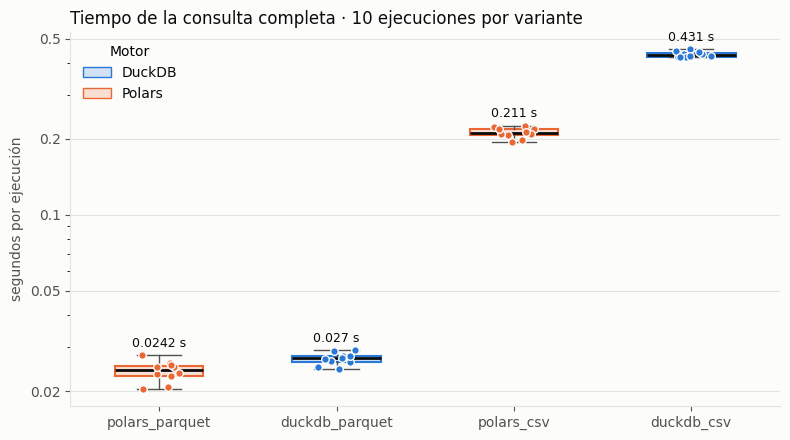

In [36]:
resumen_tiempos = (
    tiempos.group_by('variante')
    .agg(media=pl.col('segundos').mean(), mediana=pl.col('segundos').median(),
         desviacion=pl.col('segundos').std(), minimo=pl.col('segundos').min(),
         maximo=pl.col('segundos').max())
    .sort('mediana')
)
display(resumen_tiempos)

COLOR_MOTOR = {'duckdb': '#2a78d6', 'polars': '#eb6834'}
NOMBRE_MOTOR = {'duckdb': 'DuckDB', 'polars': 'Polars'}
FONDO, TEXTO, TEXTO_SECUNDARIO, REJILLA = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
orden_grafico = resumen_tiempos['variante'].to_list()
datos = [tiempos.filter(pl.col('variante') == v)['segundos'].to_numpy() for v in orden_grafico]
colores = [COLOR_MOTOR[v.split('_')[0]] for v in orden_grafico]

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=FONDO)
ax.set_facecolor(FONDO)
cajas = ax.boxplot(datos, tick_labels=orden_grafico, widths=0.5, patch_artist=True,
                   showfliers=False, medianprops={'color': TEXTO, 'linewidth': 2},
                   whiskerprops={'color': TEXTO_SECUNDARIO}, capprops={'color': TEXTO_SECUNDARIO})
puntos = np.random.default_rng(SEMILLA)
for posicion, (caja, valores, color) in enumerate(zip(cajas['boxes'], datos, colores), start=1):
    caja.set(facecolor=color + '33', edgecolor=color, linewidth=1.5)
    ax.scatter(posicion + puntos.uniform(-0.12, 0.12, len(valores)), valores, s=30,
               color=color, edgecolor=FONDO, linewidth=1, zorder=3)
    ax.annotate(f'{np.median(valores):.3g} s', (posicion, valores.max()), xytext=(0, 6),
                textcoords='offset points', ha='center', color=TEXTO, fontsize=9)
if resumen_tiempos['mediana'].max() / resumen_tiempos['mediana'].min() > 10:
    ax.set_yscale('log')
    ax.yaxis.set_major_locator(LogLocator(subs=[1, 2, 5]))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f'{valor:g}'))
    ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_title(f'Tiempo de la consulta completa · {N_EJECUCIONES} ejecuciones por variante',
             loc='left', color=TEXTO)
ax.set_ylabel('segundos por ejecución', color=TEXTO_SECUNDARIO)
ax.grid(axis='y', color=REJILLA, linewidth=0.8)
ax.set_axisbelow(True)
for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
for lado in ['left', 'bottom']:
    ax.spines[lado].set_color(REJILLA)
ax.tick_params(colors=TEXTO_SECUNDARIO)
ax.legend(handles=[Patch(facecolor=c + '33', edgecolor=c, label=NOMBRE_MOTOR[m])
                   for m, c in COLOR_MOTOR.items()],
          title='Motor', frameon=False, labelcolor=TEXTO)
plt.tight_layout()
plt.show()

## E5. Test de Friedman

**Hipótesis**

- **H0:** las cuatro variantes son estadísticamente iguales en tiempo de ejecución.
- **H1:** al menos una variante tiene tiempos distintos de las demás.

**Por qué Friedman:** es la alternativa no paramétrica al ANOVA de medidas repetidas.
No supone normalidad (los tiempos suelen tener colas largas) y trata cada ejecución
como un **bloque**: las cuatro variantes se midieron en la misma ejecución, bajo las
mismas condiciones de la máquina.

**Cómo funciona**

1. En cada ejecución (fila) se ordenan las variantes: rango 1 = la más rápida, 4 = la más lenta.
2. Se promedia el rango de cada variante en las N ejecuciones: $\bar R_j$.
3. Si H0 fuese cierta, todos los rangos medios estarían cerca de $(k+1)/2 = 2{,}5$.
4. El estadístico mide cuánto se alejan:
   $\chi^2_F = \dfrac{12N}{k(k+1)}\left[\sum_j \bar R_j^2 - \dfrac{k(k+1)^2}{4}\right]$,
   que sigue aproximadamente una $\chi^2$ con $k-1$ grados de libertad.
5. Si $p < \alpha$, se rechaza H0.

En el código:

- `pivot` pasa `tiempos` a formato **ancho**: filas = ejecuciones, columnas = variantes.
- `to_numpy()` da la matriz `X` (N × k) que espera scipy.
- `stats.rankdata` asigna los rangos dentro de cada fila (`np.apply_along_axis(..., 1, X)`).
- `stats.friedmanchisquare(*X.T)` recibe una muestra por variante (las columnas de `X`).
- Calculamos también el estadístico con la fórmula, para comprobar que es el mismo.

In [37]:
NOMBRES = list(VARIANTES)
ancho = tiempos.pivot(on='variante', index='ejecucion', values='segundos').sort('ejecucion')
X = ancho.select(NOMBRES).to_numpy()
N, k = X.shape

rangos = np.apply_along_axis(stats.rankdata, 1, X)
rango_medio = dict(zip(NOMBRES, rangos.mean(axis=0)))
chi2_formula = 12 * N / (k * (k + 1)) * (np.sum(rangos.mean(axis=0) ** 2) - k * (k + 1) ** 2 / 4)
estadistico, p_friedman = stats.friedmanchisquare(*X.T)
rechaza_h0 = p_friedman < ALFA

display(ancho)
display(pl.DataFrame({'variante': NOMBRES, 'rango_medio': rangos.mean(axis=0)}).sort('rango_medio'))
print(f'Friedman: chi² = {estadistico:.3f} (fórmula: {chi2_formula:.3f}), gl = {k - 1}, p = {p_friedman:.3e}')
print('Se rechaza H0' if rechaza_h0 else 'No se rechaza H0', f'con alfa = {ALFA}')

ejecucion,polars_parquet,duckdb_parquet,duckdb_csv,polars_csv
i64,f64,f64,f64,f64
1,0.022849,0.026194,0.433897,0.225718
2,0.023471,0.029036,0.425381,0.207106
3,0.024801,0.027564,0.436158,0.21863
4,0.020677,0.026091,0.421815,0.208829
5,0.02771,0.028843,0.453653,0.21365
6,0.023687,0.026879,0.423897,0.209238
7,0.025826,0.024435,0.446204,0.194933
8,0.025261,0.024974,0.427689,0.223991
9,0.020348,0.027621,0.422781,0.219877


variante,rango_medio
str,f64
"""polars_parquet""",1.2
"""duckdb_parquet""",1.8
"""polars_csv""",3.0
"""duckdb_csv""",4.0


Friedman: chi² = 28.080 (fórmula: 28.080), gl = 3, p = 3.494e-06
Se rechaza H0 con alfa = 0.05


## E6. Comparación post-hoc par a par

Friedman solo dice **si** hay diferencias, no **entre cuáles** variantes. Con k = 4 hay
6 pares. Comparar muchos pares aumenta la probabilidad de un falso positivo, así que
cada método controla ese error. Solo se interpretan si Friedman rechazó H0.

**1. Test de Nemenyi** (sobre los mismos rangos de Friedman)

- Error estándar de la diferencia de rangos medios: $SE = \sqrt{k(k+1)/(6N)}$.
- Para cada par, $z = |\bar R_i - \bar R_j| / SE$ y el p-valor sale de la distribución
  del **rango estudentizado** (`stats.studentized_range`, con infinitos grados de libertad).
- Equivale a decir que dos variantes difieren si sus rangos medios se separan más que
  la **diferencia crítica** $CD = \dfrac{q_\alpha}{\sqrt 2}\, SE$.

**2. Wilcoxon de rangos con signo + corrección de Holm**

- `stats.wilcoxon(a, b)` compara las diferencias reales de tiempo, ejecución a ejecución,
  entre dos variantes.
- **Holm** ordena los 6 p-valores de menor a mayor, multiplica el i-ésimo por (6 − i + 1)
  y mantiene la secuencia no decreciente. Controla el error de toda la familia de
  comparaciones y es menos estricta que Bonferroni.

**Por qué los dos:** con solo N = 10, Nemenyi es **conservador**. Si una variante queda
siempre 1.ª y otra siempre 2.ª, sus rangos medios difieren en 1, menos que CD ≈ 1,48, y
Nemenyi no las separa. Wilcoxon-Holm sí detecta esa ventaja sistemática, porque usa las
diferencias medidas en cada ejecución.

**Un detalle de N = 10:** el p-valor exacto más pequeño que puede dar Wilcoxon es
$2/2^{10} \approx 0{,}002$ (una variante gana en las 10 ejecuciones). Tras Holm, el menor
posible es ≈ 0,012. Si varios pares muestran ese mismo valor, es que en todos ellos una
variante ganó siempre.

La columna `aceleracion` es el cociente de medianas: cuántas veces es más rápida la
variante ganadora del par.

In [38]:
SE = np.sqrt(k * (k + 1) / (6 * N))
CD = stats.studentized_range.ppf(1 - ALFA, k, np.inf) / np.sqrt(2) * SE
pares = list(itertools.combinations(NOMBRES, 2))
p_wilcoxon = [stats.wilcoxon(X[:, NOMBRES.index(a)], X[:, NOMBRES.index(b)]).pvalue for a, b in pares]

def holm(p_valores):
    m = len(p_valores)
    ajustados, acumulado = [0.0] * m, 0.0
    for posicion, indice in enumerate(np.argsort(p_valores)):
        acumulado = max(acumulado, min(1.0, (m - posicion) * p_valores[indice]))
        ajustados[indice] = acumulado
    return ajustados

filas = []
for (a, b), p_w in zip(pares, holm(p_wilcoxon)):
    diferencia = abs(rango_medio[a] - rango_medio[b])
    p_n = stats.studentized_range.sf(diferencia / SE * np.sqrt(2), k, np.inf)
    mediana_a, mediana_b = np.median(X[:, NOMBRES.index(a)]), np.median(X[:, NOMBRES.index(b)])
    filas.append({'variante_a': a, 'variante_b': b,
                  'mas_rapida': a if mediana_a < mediana_b else b,
                  'dif_rangos': diferencia,
                  'p_nemenyi': float(p_n), 'nemenyi_signif': bool(p_n < ALFA),
                  'p_wilcoxon_holm': float(p_w), 'wilcoxon_signif': bool(p_w < ALFA),
                  'aceleracion': max(mediana_a, mediana_b) / min(mediana_a, mediana_b)})
posthoc = pl.DataFrame(filas).sort('dif_rangos', descending=True)
print(f'Diferencia crítica de Nemenyi: CD = {CD:.3f} rangos (k = {k}, N = {N}, alfa = {ALFA})')
display(posthoc)

Diferencia crítica de Nemenyi: CD = 1.483 rangos (k = 4, N = 10, alfa = 0.05)


variante_a,variante_b,mas_rapida,dif_rangos,p_nemenyi,nemenyi_signif,p_wilcoxon_holm,wilcoxon_signif,aceleracion
str,str,str,f64,f64,bool,f64,bool,f64
"""duckdb_csv""","""polars_parquet""","""polars_parquet""",2.8,0.000007,true,0.011719,true,17.768828
"""duckdb_csv""","""duckdb_parquet""","""duckdb_parquet""",2.2,0.000799,true,0.011719,true,15.950274
"""polars_csv""","""polars_parquet""","""polars_parquet""",1.8,0.009856,true,0.011719,true,8.721399
"""polars_csv""","""duckdb_parquet""","""duckdb_parquet""",1.2,0.160126,false,0.011719,true,7.828806
"""duckdb_csv""","""polars_csv""","""polars_csv""",1.0,0.30695,false,0.011719,true,2.037383
"""duckdb_parquet""","""polars_parquet""","""polars_parquet""",0.6,0.726349,false,0.013672,true,1.114014


## E7. Conclusión

La celda redacta la conclusión a partir de los resultados: la decisión de Friedman, el
ranking por rango medio y, para la variante más rápida, frente a cuáles su ventaja es
estadísticamente significativa según cada post-hoc.

- La variante más rápida es la de **menor rango medio**; si dos empatan, decide la mediana.
- Las variantes que **no** se distinguen de ella (Wilcoxon-Holm) forman con ella el
  **grupo más rápido**: entre ellas no hay evidencia de diferencia.

In [39]:
mediana = dict(resumen_tiempos.select('variante', 'mediana').iter_rows())
mejor = min(NOMBRES, key=lambda v: (rango_medio[v], mediana[v]))
print(f'Friedman: chi² = {estadistico:.2f}, p = {p_friedman:.3e} → ' +
      ('se rechaza H0: los tiempos de las variantes NO son iguales.' if rechaza_h0
       else 'no se rechaza H0: no hay evidencia de que los tiempos difieran.'))
print('Ranking por rango medio:',
      ', '.join(f'{v} ({r:.2f})' for v, r in sorted(rango_medio.items(), key=lambda par: par[1])))

frente = posthoc.filter((pl.col('variante_a') == mejor) | (pl.col('variante_b') == mejor))
print(f'\nVariante más rápida: {mejor}')
for fila in frente.iter_rows(named=True):
    otra = fila['variante_b'] if fila['variante_a'] == mejor else fila['variante_a']
    print(f"  vs {otra}: {fila['aceleracion']:.1f}× más rápida en mediana | "
          f"Nemenyi p = {fila['p_nemenyi']:.4f} ({'significativa' if fila['nemenyi_signif'] else 'no significativa'}) | "
          f"Wilcoxon-Holm p = {fila['p_wilcoxon_holm']:.4f} ({'significativa' if fila['wilcoxon_signif'] else 'no significativa'})")

no_separadas = [fila['variante_b'] if fila['variante_a'] == mejor else fila['variante_a']
                for fila in frente.iter_rows(named=True)
                if not fila['wilcoxon_signif'] or fila['mas_rapida'] != mejor]
if not rechaza_h0:
    print('\nConclusión: con estos datos no se puede afirmar que una opción sea más rápida que las demás.')
elif not no_separadas:
    print(f'\nConclusión: {mejor} es la opción más rápida y su ventaja es estadísticamente '
          f'significativa frente a todas las demás (Wilcoxon-Holm, alfa = {ALFA}).')
else:
    grupo = [mejor] + no_separadas
    resto = [v for v in NOMBRES if v not in grupo]
    print(f'\nConclusión: no hay una única ganadora. {", ".join(grupo)} forman el grupo más rápido: '
          f'entre ellas no hay diferencia significativa (Wilcoxon-Holm, alfa = {ALFA}).')
    if resto:
        print(f'{mejor} sí es significativamente más rápida que: {", ".join(resto)}.')

Friedman: chi² = 28.08, p = 3.494e-06 → se rechaza H0: los tiempos de las variantes NO son iguales.
Ranking por rango medio: polars_parquet (1.20), duckdb_parquet (1.80), polars_csv (3.00), duckdb_csv (4.00)

Variante más rápida: polars_parquet
  vs duckdb_csv: 17.8× más rápida en mediana | Nemenyi p = 0.0000 (significativa) | Wilcoxon-Holm p = 0.0117 (significativa)
  vs polars_csv: 8.7× más rápida en mediana | Nemenyi p = 0.0099 (significativa) | Wilcoxon-Holm p = 0.0117 (significativa)
  vs duckdb_parquet: 1.1× más rápida en mediana | Nemenyi p = 0.7263 (no significativa) | Wilcoxon-Holm p = 0.0137 (significativa)

Conclusión: polars_parquet es la opción más rápida y su ventaja es estadísticamente significativa frente a todas las demás (Wilcoxon-Holm, alfa = 0.05).


## E8. Cierre y preguntas para la clase

**Qué aprendimos**

- DuckDB (SQL declarativo) y Polars (expresiones encadenadas) resuelven la misma
  consulta con la misma estrategia: lectura diferida, solo las columnas necesarias,
  filtro temprano y ejecución en varios hilos. El resultado es idéntico, fila a fila.
- La parte más cara de la consulta sobre CSV es **leer y convertir texto**. Parquet
  guarda los datos por columnas y comprimidos: cada consulta lee mucho menos. La
  conversión se paga **una vez** y se amortiza en cada consulta posterior.
- Una sola medición no basta para decidir. Con repeticiones, orden aleatorio, Friedman
  y post-hoc la conclusión tiene respaldo estadístico. Aun así vale para **esta
  máquina, estos datos y esta consulta**.

**Para practicar**

1. Cambiar `EDAD_MINIMA` a 90 y anticipar qué tablas cambian y cuáles no.
2. Añadir `WHERE anio = 2024` a la consulta Parquet: ¿cuántas particiones lee ahora?
   ¿Cambia el tiempo? (poda de particiones).
3. Agrupar por `afec_cod_depto` (departamento de la persona afectada) en lugar de
   `pet_cod_depto` y comparar los dos rankings.
4. Agrupar solo por `mes`, sin el año, y explicar qué meses se mezclan.
5. Subir `N_EJECUCIONES` a 20: ¿cambia la diferencia crítica de Nemenyi? ¿Y las conclusiones?